# Experiment 2: K-Means Classifier vs. Random Forest vs ** Cat Boost** on the Breast Cancer Dataset

This notebook compares two classifiers, each with and without PCA:

1. **K-Means used as a classifier.** My implementation on k means I am curious on how it does relative to state of the art sci-kit-learn library made by some random MIT phd candidate.
   
2. **Random Forest** .

For the k means with our tuning, we are using k and for Random Forest Tree we are tuning with min_sample_leaf

**Cat Boost**

**Confusion Matrix** Confusion matrix with pthon print formatting. :




In [55]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from harrison_kit_learn.k_means import k_means

def print_confusion(label, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print(f"  Confusion matrix ({label}) [rows=actual, cols=predicted]")
    print(f"                 Pred 0   Pred 1")
    print(f"    Actual 0     {cm[0,0]:6d}   {cm[0,1]:6d}   (TN, FP)")
    print(f"    Actual 1     {cm[1,0]:6d}   {cm[1,1]:6d}   (FN, TP)")
    return cm


## 1. Load and prepare the data

From `breast-cancer.csv` we drop the `id` column and the empty `Unnamed: 32` column. The `diagnosis` column (M/B) becomes a numeric **`Class`** label: **1 = malignant, 0 = benign**. The original `diagnosis` column is then dropped so it cannot be used as a feature.

In [56]:
# Read the breast-cancer dataset
df = pd.read_csv("breast-cancer.csv")

# Drop Id columns and Unamed 32 
df = df.drop(columns=["id", "Unnamed: 32"])

df["Class"] = (df["diagnosis"] == "M").astype(int)
df = df.drop(columns="diagnosis")

Quick look at the first rows.

In [57]:
df.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Class
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2. Splitting the data

**`split_sets`** We divide the data by one-third then we shuffle them ysing a random state. I decided to use state 42. I shuffled it since the data could be stacked between classifications. Then after that I got my regular sets then I split into my pca sets. I return all 6 sets. 

In [58]:
# You can chose the number of components you want but for this is chose a default of 8
def split_sets(df, n_components=8):
    
    # Get the total number of rows
    total_numb_rows = len(df)

    # Splitting by 1/3 will allow me to get each set.
    one_third_length_rows = int(total_numb_rows / 3)

    # Shuffle the data set I chose randomstate 42 so we are getting the exact same shuffle 
    df_shuffled = df.sample(frac=1, ignore_index=True, random_state=42)

    # My training set without the dimension reduction.
    training_set = df_shuffled[:one_third_length_rows]
    validation_set = df_shuffled[one_third_length_rows:one_third_length_rows * 2]
    testing_set = df_shuffled[one_third_length_rows * 2:]

    feature_cols = [c for c in training_set.columns if c != "Class"]
    pc_cols = [f"PC{i + 1}" for i in range(n_components)]



    # The dimension reduced dataset 
    pca = PCA(n_components=n_components)

    training_pca = pd.DataFrame(pca.fit_transform(training_set[feature_cols]), columns=pc_cols)
    validation_pca = pd.DataFrame(pca.transform(validation_set[feature_cols]), columns=pc_cols)
    testing_pca = pd.DataFrame(pca.transform(testing_set[feature_cols]), columns=pc_cols)

    training_pca["Class"] = training_set["Class"].to_numpy()
    validation_pca["Class"] = validation_set["Class"].to_numpy()
    testing_pca["Class"] = testing_set["Class"].to_numpy()


    # Reutrunng all of the dataesets. 
    return (training_set, validation_set, testing_set,
            training_pca, validation_pca, testing_pca)


## 3. K-Means as a classifier

Since k means is unsupervised based on my implementation i had to add extra code. 

- **`get_cluster_labels`** each point will go to its nearest cener, assign each cluster the majority class. 
- **`predict_k_means`** a new point is classified with it's nearest center.

In [59]:
# Getting the lables of the clusters
def get_cluster_labels(centers, x_np, y_np):
    # Cluster lables and indexes is currently emptpy
    cluster_labels = []
    cluster_indexes = []

    # Assign each point's 
    for each_point in x_np:
        distances = []
        for each_center in centers:
            distances.append(np.linalg.norm(each_point - each_center))
        # Get the index of the cluster with the smallest distance. This will basically hold all of the index
        cluster_indexes.append(distances.index(min(distances)))

   
    cluster_indexes = np.array(cluster_indexes)
    overall_majority = int(round(y_np.mean()))

    for cluster in range(len(centers)):
        cluster_y = y_np[cluster_indexes == cluster]
        if len(cluster_y) == 0:
            cluster_labels.append(overall_majority)
        else:
            cluster_labels.append(int(round(cluster_y.mean())))

    return cluster_labels

# This will make a prediction based off my centers. 
def predict_k_means(centers, cluster_labels, x_np):
    # Predictions before accumulation. 
    predictions = []

    # Loop through every point that does not include the classificaiton. which is my diagnosis column
    for each_point in x_np:
        # Make empty list of distances 
        distances = []
        # Get all the distances from the center. 
        for each_center in centers:
            distances.append(np.linalg.norm(each_point - each_center))
        # Append the prediction wit the smallest distance which means that this it's centroid group,
        predictions.append(cluster_labels[distances.index(min(distances))])

    # Predicitons in numpy aray. 
    return np.array(predictions)


**`get_best_k_means`** tunes k:

1. Splitting the set into testing validation, and, non validation
2. Apply normalization
3. Intiate the k which is current at 2
4. Fine tune for k with highest validation score.
5. Use the best k for the testing set. 


In [60]:
def get_best_k_means(training_set, validation_set, testing_set):
    # These are the numbers of clusters (k) we will try
    k_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16, 20]
    iteration = 0

    # This is where we store each k and its F1 scores so we can graph them later
    results = {'params': [], 'train_f1': [], 'val_f1': []}

    # TRAINING SET X, Y

    # This will be each person excluding Class
    training_set_x = training_set.drop(columns="Class")

    # This will be only the Class of each person
    training_set_y = training_set['Class']

    # This is the numpy array of the training set
    training_set_x_np = training_set_x.to_numpy()
    training_set_y_np = training_set_y.to_numpy()


    # VALIDATION SET X, Y

    # This will be each person excluding Class
    validation_set_x = validation_set.drop(columns="Class")

    # This will be only the Class of each person
    validation_set_y = validation_set['Class']

    # This is the numpy array of the validation set
    validation_set_x_np = validation_set_x.to_numpy()
    validation_set_y_np = validation_set_y.to_numpy()


    # TESTING SET X, Y

    # This will be each person excluding Class
    testing_set_x = testing_set.drop(columns="Class")

    # This will be only the Class of each person
    testing_set_y = testing_set['Class']

    # This is the numpy array of the testing set
    testing_set_x_np = testing_set_x.to_numpy()
    testing_set_y_np = testing_set_y.to_numpy()


    # Normalize the data with sklearn. The scaler is fit on the training set only,
    # then applied to validation and testing so no information leaks from them.
    scaler = MinMaxScaler()
    training_set_x_np = scaler.fit_transform(training_set_x_np)
    validation_set_x_np = scaler.transform(validation_set_x_np)
    testing_set_x_np = scaler.transform(testing_set_x_np)


    # This is where we will store the best k, updated as we find better validation scores.
    # Right now it is the first k but it will more than likely update
    best_k = k_values[0]
    current_best_f1 = 0

    # Loop over every k in k_values. We pick the best k based on the validation set
    # because that lets us know whether or not we are overfitting.
    while (iteration < len(k_values)):
        # Seed so each k starts from the same random state, then find the k centers using the training set
        np.random.seed(42)
        centers, inertias = k_means(k_values[iteration], training_set_x_np)

        # Each cluster gets the majority Class of the training points closest to its center
        cluster_labels = get_cluster_labels(centers, training_set_x_np, training_set_y_np)

        # Training set prediction. We calculate the F1 score of the training set, this should usually be higher than validation.
        training_set_predicition = predict_k_means(centers, cluster_labels, training_set_x_np)
        training_f1 = f1_score(training_set_y_np, training_set_predicition)

        # Using those same centers and cluster labels, get the prediction on the validation set
        validation_set_predicition = predict_k_means(centers, cluster_labels, validation_set_x_np)
        validation_f1 = f1_score(validation_set_y_np, validation_set_predicition)

        # If the current validation score is higher than the current highest, update it.
        # We also update the best k
        if validation_f1 > current_best_f1:
            current_best_f1 = validation_f1
            best_k = k_values[iteration]

        print(f"Iteration: {iteration + 1}; with Number of Clusters: {k_values[iteration]}; F1 Score (Training Set): {training_f1}, F1 Score (Validation Set) {validation_f1}")


        print("")

        # Save this iteration so we can graph it later
        results['params'].append(k_values[iteration])
        results['train_f1'].append(training_f1)
        results['val_f1'].append(validation_f1)

        iteration += 1


    # Once we finish iterating, rerun k-means at the best k using the training set only
    np.random.seed(42)
    best_centers, best_inertias = k_means(best_k, training_set_x_np)
    best_cluster_labels = get_cluster_labels(best_centers, training_set_x_np, training_set_y_np)

    # Now we use the best centers to predict the testing set and get its F1 score
    testing_set_predicition = predict_k_means(best_centers, best_cluster_labels, testing_set_x_np)
    testing_f1 = f1_score(testing_set_y_np, testing_set_predicition)

    print("")
    print("Final Result")
    print(f"Number of Clusters: {best_k}; F1 Score (Testing Set): {testing_f1}")

    # Confusion matrix for the testing set
    test_cm = print_confusion("Testing", testing_set_y_np, testing_set_predicition)

    results['best_param'] = best_k
    results['test_f1'] = testing_f1
    results['test_cm'] = test_cm
    return results


## 4. Random Forest

**`get_best_depth_random_forest_tree`** Does the same as k means. 

In [61]:
def get_best_depth_random_forest_tree(training_set, validation_set, testing_set):
    # These are the minimum leaf sizes we will try, from simplest (large leaves) to most complex (leaf size 1)
    leaf_sizes = [100, 75, 50, 35, 25, 20, 15, 10, 8, 5, 3, 2, 1]
    iteration = 0

    # This is where we store each leaf size and its F1 scores so we can graph them later
    results = {'params': [], 'train_f1': [], 'val_f1': []}

    # TRAINING SET X, Y

    # This will be each person excluding Class
    training_set_x = training_set.drop(columns="Class")

    # This will be only the Class of each person
    training_set_y = training_set['Class']

    # This is the numpy array of the training set
    training_set_x_np = training_set_x.to_numpy()
    training_set_y_np = training_set_y.to_numpy()


    # VALIDATION SET X, Y

    # This will be each person excluding Class
    validation_set_x = validation_set.drop(columns="Class")

    # This will be only the Class of each person
    validation_set_y = validation_set['Class']

    # This is the numpy array of the validation set
    validation_set_x_np = validation_set_x.to_numpy()
    validation_set_y_np = validation_set_y.to_numpy()


    # TESTING SET X, Y

    # This will be each person excluding Class
    testing_set_x = testing_set.drop(columns="Class")

    # This will be only the Class of each person
    testing_set_y = testing_set['Class']

    # This is the numpy array of the testing set
    testing_set_x_np = testing_set_x.to_numpy()
    testing_set_y_np = testing_set_y.to_numpy()


    # This is where we will store the best leaf size, updated as we find better validation scores.
    # Right now it is the first leaf size but it will more than likely update
    best_min_sample_leaf = leaf_sizes[0]
    current_best_f1 = 0

    # Loop over every leaf size in leaf_sizes
    while (iteration < len(leaf_sizes)):
        # We fit a random forest at each leaf size using the training set only
        current_decision_tree = RandomForestClassifier(min_samples_leaf=leaf_sizes[iteration], class_weight="balanced", random_state=42)
        current_decision_tree = current_decision_tree.fit(training_set_x_np, training_set_y_np)


        # Training set prediction. We calculate the F1 score of the training set, this should usually be higher than validation.
        training_set_predicition = current_decision_tree.predict(training_set_x_np.tolist())
        training_f1 = f1_score(training_set_y_np, training_set_predicition)

        # Using that fitted forest, get the prediction on the validation set
        validation_set_predicition = current_decision_tree.predict(validation_set_x_np.tolist())
        validation_f1 = f1_score(validation_set_y_np, validation_set_predicition)

        # If the current validation score is higher than the current highest, update it.
        # We also update the best min sample leaf
        if validation_f1 > current_best_f1:
            current_best_f1 = validation_f1
            best_min_sample_leaf = leaf_sizes[iteration]

        print(f"Iteration: {iteration + 1}; with Mininum Leaf Size: {leaf_sizes[iteration]}; F1 Score (Training Set): {training_f1}, F1 Score (Validation Set) {validation_f1}")


        print("")

        # Save this iteration so we can graph it later
        results['params'].append(leaf_sizes[iteration])
        results['train_f1'].append(training_f1)
        results['val_f1'].append(validation_f1)

        iteration += 1


    # Once we finish iterating, refit the best forest on the TRAINING set only (never the testing set)
    best_tree = RandomForestClassifier(min_samples_leaf=best_min_sample_leaf, class_weight="balanced", random_state=42)
    best_tree = best_tree.fit(training_set_x_np, training_set_y_np)

    # Now we use the best forest to predict the testing set and get its F1 score
    testing_set_predicition = best_tree.predict(testing_set_x_np.tolist())
    testing_f1 = f1_score(testing_set_y_np, testing_set_predicition)

    print("")
    print("Final Result")
    print(f"Minimum Leaf Size: {best_min_sample_leaf}; F1 Score (Testing Set): {testing_f1}")

    # Confusion matrix for the testing set
    test_cm = print_confusion("Testing", testing_set_y_np, testing_set_predicition)

    results['best_param'] = best_min_sample_leaf
    results['test_f1'] = testing_f1
    results['test_cm'] = test_cm
    return results


## 5. CatBoost

**`get_best_depth_catboost_tree`** Does the same as k means and Random Forest, but tunes the tree depth of a CatBoost model (10 iterations)

In [62]:
def get_best_depth_catboost_tree(training_set, validation_set, testing_set):
    # These are the tree depths we will try, from simplest (depth 1) to most complex (depth 10)
    depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
    iteration = 0

    # This is where we store each depth and its F1 scores so we can graph them later
    results = {'params': [], 'train_f1': [], 'val_f1': []}

    # TRAINING SET X, Y

    # This will be each person excluding Class
    training_set_x = training_set.drop(columns="Class")

    # This will be only the Class of each person
    training_set_y = training_set['Class']

    # This is the numpy array of the training set
    training_set_x_np = training_set_x.to_numpy()
    training_set_y_np = training_set_y.to_numpy()


    # VALIDATION SET X, Y

    # This will be each person excluding Class
    validation_set_x = validation_set.drop(columns="Class")

    # This will be only the Class of each person
    validation_set_y = validation_set['Class']

    # This is the numpy array of the validation set
    validation_set_x_np = validation_set_x.to_numpy()
    validation_set_y_np = validation_set_y.to_numpy()


    # TESTING SET X, Y

    # This will be each person excluding Class
    testing_set_x = testing_set.drop(columns="Class")

    # This will be only the Class of each person
    testing_set_y = testing_set['Class']

    # This is the numpy array of the testing set
    testing_set_x_np = testing_set_x.to_numpy()
    testing_set_y_np = testing_set_y.to_numpy()


    # This is where we will store the best depth, updated as we find better validation scores.
    # Right now it is the first depth but it will more than likely update
    best_depth = depths[0]
    current_best_f1 = 0

    # Loop over every depth in depths
    while (iteration < len(depths)):
        # We fit a CatBoost model at each depth using the training set only
        current_catboost = CatBoostClassifier(depth=depths[iteration], iterations=100, auto_class_weights="Balanced", random_seed=42, verbose=0)
        current_catboost = current_catboost.fit(training_set_x_np, training_set_y_np)


        # Training set prediction. We calculate the F1 score of the training set, this should usually be higher than validation.
        training_set_predicition = current_catboost.predict(training_set_x_np.tolist())
        training_f1 = f1_score(training_set_y_np, training_set_predicition)

        # Using that fitted CatBoost model, get the prediction on the validation set
        validation_set_predicition = current_catboost.predict(validation_set_x_np.tolist())
        validation_f1 = f1_score(validation_set_y_np, validation_set_predicition)

        # If the current validation score is higher than the current highest, update it.
        # We also update the best depth
        if validation_f1 > current_best_f1:
            current_best_f1 = validation_f1
            best_depth = depths[iteration]

        print(f"Iteration: {iteration + 1}; with Depth: {depths[iteration]}; F1 Score (Training Set): {training_f1}, F1 Score (Validation Set) {validation_f1}")


        print("")

        # Save this iteration so we can graph it later
        results['params'].append(depths[iteration])
        results['train_f1'].append(training_f1)
        results['val_f1'].append(validation_f1)

        iteration += 1


    # Once we finish iterating, refit the best CatBoost model on the TRAINING set only (never the testing set)
    best_catboost = CatBoostClassifier(depth=best_depth, iterations=100, auto_class_weights="Balanced", random_seed=42, verbose=0)
    best_catboost = best_catboost.fit(training_set_x_np, training_set_y_np)

    # Now we use the best CatBoost model to predict the testing set and get its F1 score
    testing_set_predicition = best_catboost.predict(testing_set_x_np.tolist())
    testing_f1 = f1_score(testing_set_y_np, testing_set_predicition)

    print("")
    print("Final Result")
    print(f"Depth: {best_depth}; F1 Score (Testing Set): {testing_f1}")

    # Confusion matrix for the testing set
    test_cm = print_confusion("Testing", testing_set_y_np, testing_set_predicition)

    results['best_param'] = best_depth
    results['test_f1'] = testing_f1
    results['test_cm'] = test_cm
    return results


## 5. Build the datasets

Splitting the sets like experiment one 

In [63]:
(training_set, validation_set, testing_set, training_pca, validation_pca, testing_pca) = split_sets(df)


## 6. Run the experiments

Running on each of the six sets to get result. 
**K-Means, non-PCA features**

In [64]:
km_no_dim_reduct = get_best_k_means(training_set, validation_set, testing_set)

Iteration: 1; with Number of Clusters: 2; F1 Score (Training Set): 0.8818897637795275, F1 Score (Validation Set) 0.873015873015873

Iteration: 2; with Number of Clusters: 3; F1 Score (Training Set): 0.75, F1 Score (Validation Set) 0.7719298245614035

Iteration: 3; with Number of Clusters: 4; F1 Score (Training Set): 0.8264462809917356, F1 Score (Validation Set) 0.8387096774193549

Iteration: 4; with Number of Clusters: 5; F1 Score (Training Set): 0.8305084745762712, F1 Score (Validation Set) 0.8666666666666667

Iteration: 5; with Number of Clusters: 6; F1 Score (Training Set): 0.8872180451127819, F1 Score (Validation Set) 0.8923076923076924

Iteration: 6; with Number of Clusters: 7; F1 Score (Training Set): 0.8333333333333334, F1 Score (Validation Set) 0.8666666666666667

Iteration: 7; with Number of Clusters: 8; F1 Score (Training Set): 0.8787878787878788, F1 Score (Validation Set) 0.8818897637795275

Iteration: 8; with Number of Clusters: 9; F1 Score (Training Set): 0.878787878787878

**K-Means, PCA features (8 components)**

In [65]:
km_pca = get_best_k_means(training_pca, validation_pca, testing_pca)

Iteration: 1; with Number of Clusters: 2; F1 Score (Training Set): 0.5833333333333334, F1 Score (Validation Set) 0.7407407407407407

Iteration: 2; with Number of Clusters: 3; F1 Score (Training Set): 0.4318181818181818, F1 Score (Validation Set) 0.5376344086021505

Iteration: 3; with Number of Clusters: 4; F1 Score (Training Set): 0.6138613861386139, F1 Score (Validation Set) 0.7522935779816514

Iteration: 4; with Number of Clusters: 5; F1 Score (Training Set): 0.6666666666666666, F1 Score (Validation Set) 0.7747747747747747

Iteration: 5; with Number of Clusters: 6; F1 Score (Training Set): 0.7619047619047619, F1 Score (Validation Set) 0.8169014084507042

Iteration: 6; with Number of Clusters: 7; F1 Score (Training Set): 0.6792452830188679, F1 Score (Validation Set) 0.7433628318584071

Iteration: 7; with Number of Clusters: 8; F1 Score (Training Set): 0.8235294117647058, F1 Score (Validation Set) 0.8769230769230769

Iteration: 8; with Number of Clusters: 9; F1 Score (Training Set): 0.

**Random Forest, non-PCA features**

In [66]:
rf_no_dim_reduct = get_best_depth_random_forest_tree(training_set, validation_set, testing_set)

Iteration: 1; with Mininum Leaf Size: 100; F1 Score (Training Set): 0.5291828793774319, F1 Score (Validation Set) 0.5291828793774319

Iteration: 2; with Mininum Leaf Size: 75; F1 Score (Training Set): 0.5291828793774319, F1 Score (Validation Set) 0.5291828793774319

Iteration: 3; with Mininum Leaf Size: 50; F1 Score (Training Set): 0.9295774647887324, F1 Score (Validation Set) 0.8823529411764706

Iteration: 4; with Mininum Leaf Size: 35; F1 Score (Training Set): 0.9496402877697842, F1 Score (Validation Set) 0.8805970149253731

Iteration: 5; with Mininum Leaf Size: 25; F1 Score (Training Set): 0.9496402877697842, F1 Score (Validation Set) 0.8805970149253731

Iteration: 6; with Mininum Leaf Size: 20; F1 Score (Training Set): 0.9496402877697842, F1 Score (Validation Set) 0.9022556390977443

Iteration: 7; with Mininum Leaf Size: 15; F1 Score (Training Set): 0.9496402877697842, F1 Score (Validation Set) 0.9090909090909091

Iteration: 8; with Mininum Leaf Size: 10; F1 Score (Training Set): 0

**Random Forest, PCA features (8 components)**

In [67]:
rf_pca = get_best_depth_random_forest_tree(training_pca, validation_pca, testing_pca)

Iteration: 1; with Mininum Leaf Size: 100; F1 Score (Training Set): 0.5291828793774319, F1 Score (Validation Set) 0.5291828793774319

Iteration: 2; with Mininum Leaf Size: 75; F1 Score (Training Set): 0.5291828793774319, F1 Score (Validation Set) 0.5291828793774319

Iteration: 3; with Mininum Leaf Size: 50; F1 Score (Training Set): 0.8918918918918919, F1 Score (Validation Set) 0.851063829787234

Iteration: 4; with Mininum Leaf Size: 35; F1 Score (Training Set): 0.918918918918919, F1 Score (Validation Set) 0.8591549295774648

Iteration: 5; with Mininum Leaf Size: 25; F1 Score (Training Set): 0.9054054054054054, F1 Score (Validation Set) 0.8840579710144928

Iteration: 6; with Mininum Leaf Size: 20; F1 Score (Training Set): 0.9054054054054054, F1 Score (Validation Set) 0.8633093525179856

Iteration: 7; with Mininum Leaf Size: 15; F1 Score (Training Set): 0.9379310344827586, F1 Score (Validation Set) 0.8759124087591241

Iteration: 8; with Mininum Leaf Size: 10; F1 Score (Training Set): 0.9

**CatBoost, non-PCA features**

In [68]:
cb_no_dim_reduct = get_best_depth_catboost_tree(training_set, validation_set, testing_set)

Iteration: 1; with Depth: 1; F1 Score (Training Set): 0.9784172661870504, F1 Score (Validation Set) 0.9037037037037037

Iteration: 2; with Depth: 2; F1 Score (Training Set): 1.0, F1 Score (Validation Set) 0.9264705882352942

Iteration: 3; with Depth: 3; F1 Score (Training Set): 1.0, F1 Score (Validation Set) 0.948905109489051

Iteration: 4; with Depth: 4; F1 Score (Training Set): 1.0, F1 Score (Validation Set) 0.9333333333333333

Iteration: 5; with Depth: 5; F1 Score (Training Set): 1.0, F1 Score (Validation Set) 0.9333333333333333

Iteration: 6; with Depth: 6; F1 Score (Training Set): 1.0, F1 Score (Validation Set) 0.9253731343283582

Iteration: 7; with Depth: 7; F1 Score (Training Set): 1.0, F1 Score (Validation Set) 0.9411764705882353

Iteration: 8; with Depth: 8; F1 Score (Training Set): 1.0, F1 Score (Validation Set) 0.9264705882352942

Iteration: 9; with Depth: 9; F1 Score (Training Set): 1.0, F1 Score (Validation Set) 0.9264705882352942

Iteration: 10; with Depth: 10; F1 Score (

**CatBoost, PCA features (8 components)**

In [69]:
cb_pca = get_best_depth_catboost_tree(training_pca, validation_pca, testing_pca)

Iteration: 1; with Depth: 1; F1 Score (Training Set): 0.935251798561151, F1 Score (Validation Set) 0.8823529411764706

Iteration: 2; with Depth: 2; F1 Score (Training Set): 0.9565217391304348, F1 Score (Validation Set) 0.9022556390977443

Iteration: 3; with Depth: 3; F1 Score (Training Set): 0.9927007299270073, F1 Score (Validation Set) 0.9090909090909091

Iteration: 4; with Depth: 4; F1 Score (Training Set): 0.9855072463768116, F1 Score (Validation Set) 0.9022556390977443

Iteration: 5; with Depth: 5; F1 Score (Training Set): 0.9927007299270073, F1 Score (Validation Set) 0.9022556390977443

Iteration: 6; with Depth: 6; F1 Score (Training Set): 0.9927007299270073, F1 Score (Validation Set) 0.8872180451127819

Iteration: 7; with Depth: 7; F1 Score (Training Set): 0.9927007299270073, F1 Score (Validation Set) 0.9022556390977443

Iteration: 8; with Depth: 8; F1 Score (Training Set): 0.9927007299270073, F1 Score (Validation Set) 0.9104477611940298

Iteration: 9; with Depth: 9; F1 Score (Tr

## 7. F1 graphs

One figure per algorithm. The left panel shows **training** F1 and the right panel shows **validation** F1, each with a non-PCA line and a PCA line.

The x-axis follows the order of the tuning list (k increasing for K-Means, `min_samples_leaf` decreasing for the Random Forest, so complexity increases to the right in both cases). Points are evenly spaced even though the values are not.

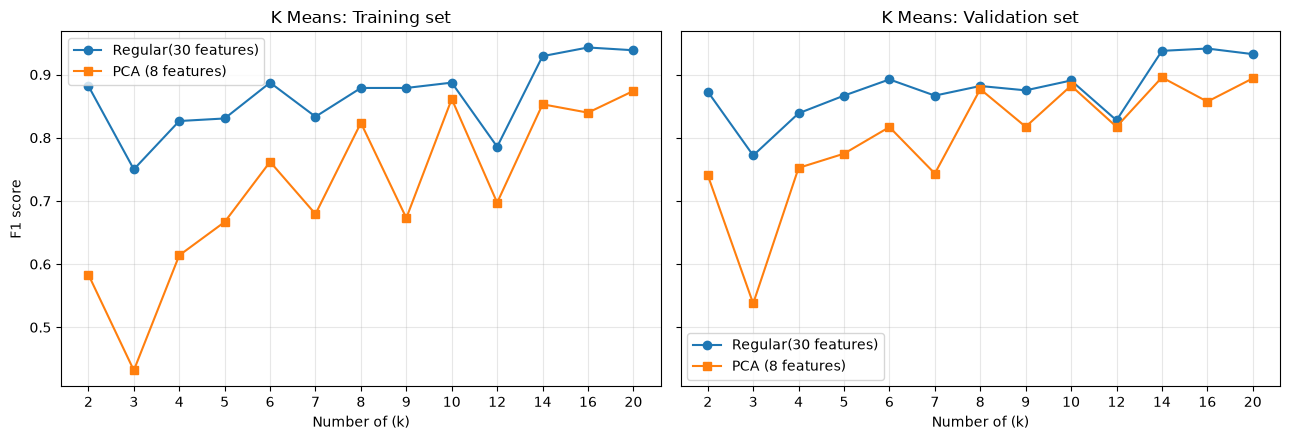

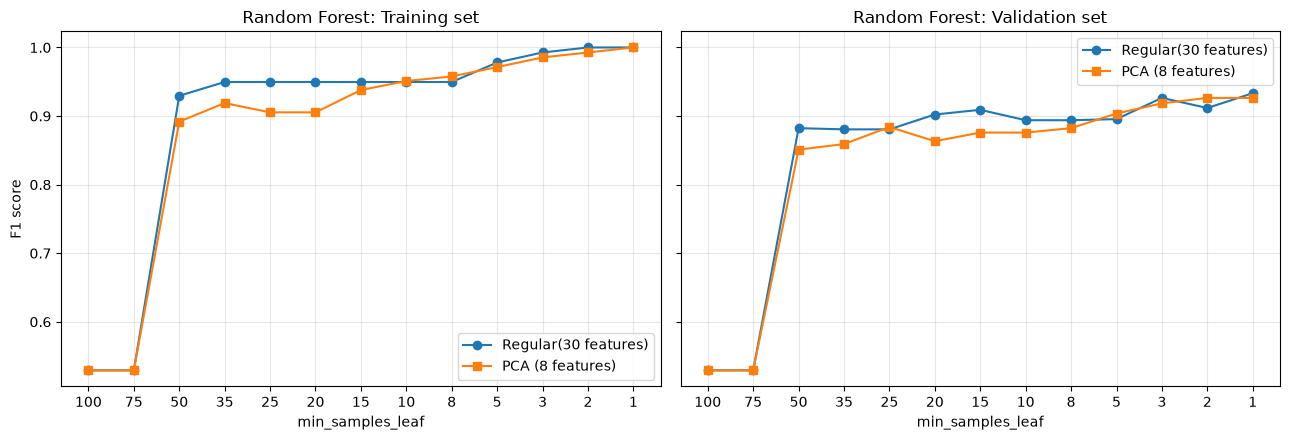

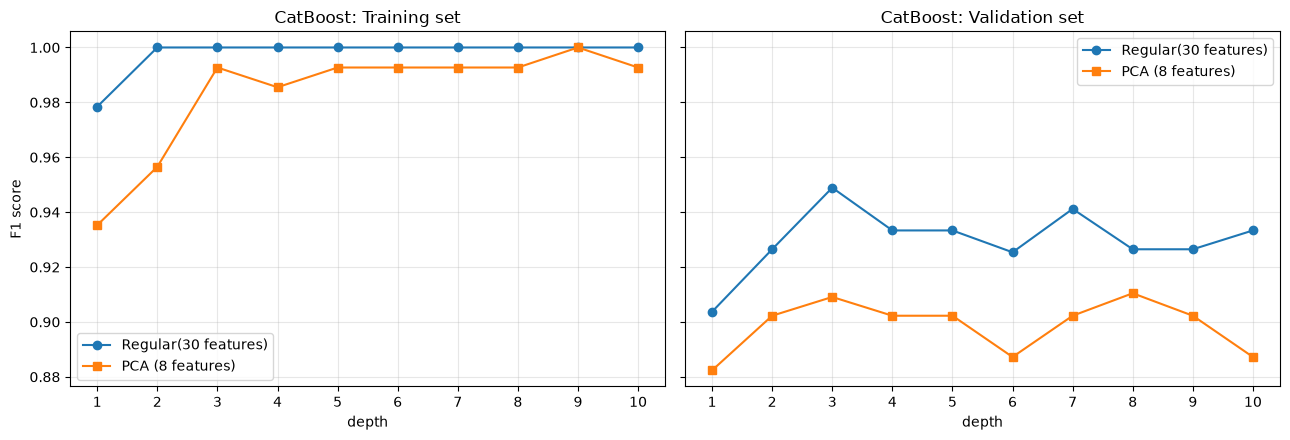

In [70]:
def plot_f1(raw, pca, title, xlabel, log_x=False, invert_x=False):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, key, name in zip(axes, ["train_f1", "val_f1"], ["Training set", "Validation set"]):
        ax.plot(range(len(raw["params"])), raw[key], marker="o", label="Regular(30 features)")
        ax.plot(range(len(pca["params"])), pca[key], marker="s", label="PCA (8 features)")
        ax.set_xticks(range(len(raw["params"])))
        ax.set_xticklabels(raw["params"])
        ax.set_title(f"{title}: {name}")
        ax.set_xlabel(xlabel)
        ax.grid(alpha=0.3)
        ax.legend()
    axes[0].set_ylabel("F1 score")
    plt.tight_layout()
    plt.show()

plot_f1(km_no_dim_reduct, km_pca, "K Means", "Number of (k)")
plot_f1(rf_no_dim_reduct, rf_pca, "Random Forest", "min_samples_leaf")
plot_f1(cb_no_dim_reduct, cb_pca, "CatBoost", "depth")


## 8. Feature importance

Feature importance for each type of tree excluding my implementation for k means since there is no built in library for that. 

In [71]:
# Refit each model at its best tuned value (training set only) and get its built-in feature importances
def get_feature_importances(training_set, rf_results, cb_results):
    train_x = training_set.drop(columns="Class").to_numpy()
    train_y = training_set["Class"].to_numpy()

    # Feature importance for random forest
    rf = RandomForestClassifier(min_samples_leaf=rf_results["best_param"], class_weight="balanced", random_state=42)
    rf = rf.fit(train_x, train_y)

    # Feature importance for cat boost
    cb = CatBoostClassifier(depth=cb_results["best_param"], iterations=100, auto_class_weights="Balanced", random_seed=42, verbose=0)
    cb = cb.fit(train_x, train_y)

    return {
        "Random Forest": rf.feature_importances_,
        "CatBoost": cb.get_feature_importance(),
    }


# Plottg my feature importance
def plot_feature_importance(importances, feature_names, title, top_n=10):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, (name, values) in zip(axes, importances.items()):
        order = np.argsort(values)[::-1][:top_n][::-1]
        ax.barh([feature_names[i] for i in order], values[order])
        ax.set_title(name)
        ax.set_xlabel("Feature Importance")
        ax.grid(alpha=0.3, axis="x")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

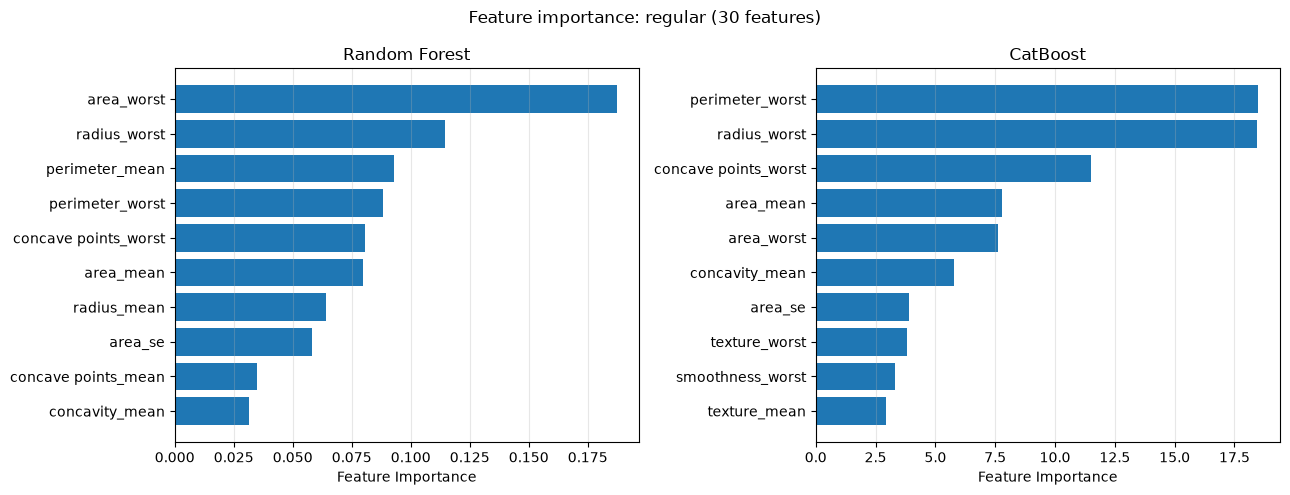

In [72]:
raw_feature_names = list(training_set.drop(columns="Class").columns)
raw_importances = get_feature_importances(training_set, rf_no_dim_reduct, cb_no_dim_reduct)
plot_feature_importance(raw_importances, raw_feature_names, "Feature importance: regular (30 features)")

## 9. Analysis: K-Means vs. Random Forest vs. CatBoost on Breast Cancer (with and without PCA)

**Setup.** Theres is 569 patients in the data, I chose a random stat of 42 for the state shuffle so all random sets are the same: Of the sets there is 189 training, 189 validation, and 191 test. Within the testing set there is (115 benign, 76 malignant). The sample set is tiny so f1 is easily impacted, so **one misclassified test row moves F1 by about 0.5 to 1 point.** I read every difference below with that in mind.

| Model | Best setting | Val F1 | Test F1 | FP | FN |
|---|---|---|---|---|---|
| K Means (mine), raw | k=16 | 0.941 | 0.933 | 4 | 6 |
| Random Forest Tree, raw | leaf=1 | 0.933 | 0.927 | 5 | 6 |
| Cat Boost Tree, raw | depth=3 | 0.949 | 0.922 | 7 | 5 |
| K-Means with PCA Dimension Reduciton | k=14 | 0.896 | 0.808 | 11 | 17 |
| Random Forest with PCA PCA Dimension Reduction | leaf=2 | 0.926 | 0.901 | 7 | 8 |
| CatBoost with PCA Dimension Reduction | depth=8 | 0.910 | 0.889 | 9 | 8 |

**1. Variance dominates on small data.** Each the Cat Tree and the Random Forest reaches an F1 score of 1, When it is time to test the dataset there is only .92 and .93. Géron's In our book, it is described that decision trees are greedy thereore it makes sense that constricted trees lead up to 1 in f1 score. This differs from the creid card data set in a sense where, there is not 190 rows in a training set like how it is in the cancer datatset. Therefore, bagging cannot solve the problem. In the cancer data set a lot of the errors overlap. 


**2. K-Means.** Based on my implementation each cluseter is assigned to the majority voted class. Based off the print statements f1 score are also very volatile from k = 2 to 12, which potentially could mean that the assignment of initial clusters are potentially very impactful in how tghe model performes in terms of finding the right k. This shows that K means could also be very erratic and you dont always get the global optium. 


**3. Medical interpretation.** The models without PCA miss about 5 of the 76 malignant cases This achieved a recall of about 92 percent. A tree-based model estimates class probabilities from the class ratio in a leaf, Based off what we talked about in class regarding type i errors an type ii errors, it would make sense to potentially decrease the threshold for more false positives in terms of malicious tumor, since it better safe than sorry to classify as malignant than benign. In a real word scenario, the doctor should play the role as an audit, while my forest while the tree plays as a white/black box algorithm. 

**6. Connecting both experiments.** In terms of sample size these were the two opposites. The credit card fraud has 190,000 rows, therefore the issue become bias: The breast cancer set had 190 rows, therfore the variance was a huge problem: In the credit card fraud dataset as tree grew more the f1 gap between validation and training narrowed down, but since there was a lot of noise in cancer dataset, validation sometimes had a hard time catching up to training set f1 score. 